# Лабораторная работа 1
## Иерархический кластерный анализ

Выполнил: Ларин Сергей Эдуардович, 563456


## Цель работы

Выделить группы городов со схожими экономическими показателями
методом иерархического кластерного анализа. Обосновать число
кластеров и дать содержательную интерпретацию полученных групп.

## Описание данных

Исследуются экономические показатели 48 городов мира за 1991 год.

В таблице представлены следующие столбцы:

1. City: название города.
2. Work: взвешенное среднее число рабочих часов по 12 профессиям.
3. Price: индекс цен на 112 товаров и услуг с учётом аренды жилья.
4. Salary: индекс почасовой заработной платы по 12 профессиям
   после налогов и отчислений.

Для индексов Price и Salary за базу принят Цюрих со значением 100.
Период измерения рабочих часов в описании данных не указан.

Название города используется для обозначения наблюдений.
Кластеризация будет выполняться по числовым показателям.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11
pd.set_option("display.max_columns", None)

## 1. Загрузка и первичный просмотр данных

Загрузим таблицу и проверим названия столбцов, размер данных
и типы переменных. Это необходимо, чтобы убедиться в корректном
чтении файла перед дальнейшим анализом.

In [9]:
import pandas as pd

file_path = r"C:\Users\sergey\Documents\lab01\Econom_Cities_data.csv"

# Загружаем данные.
df = pd.read_csv(file_path, sep=";", decimal=",")

# Сохраняем исходные данные отдельно.
df_original = df.copy()

# Проверяем результат.
display(df.head())

,City,Work,Price,Salary
0,Amsterdam,1714,65.6,49.0
1,Athens,1792,53.8,30.4
2,Bogota,2152,37.9,11.5
3,Bombay,2052,30.3,5.3
4,Brussels,1708,73.8,50.5


## 2. Проверка исходных данных

Перед кластеризацией необходимо проверить размер таблицы,
типы признаков, пропуски и повторяющиеся наблюдения.

Ошибки в исходных данных могут исказить расстояния между городами
и повлиять на состав кластеров.

In [10]:
# Список признаков, которые будем использовать для кластеризации.
features = ["Work", "Price", "Salary"]

# Проверяем количество наблюдений и столбцов.
print("Количество городов:", df.shape[0])
print("Количество столбцов:", df.shape[1])

# Выводим типы данных и количество заполненных значений.
print("\nИнформация о таблице:")
df.info()

# Проверяем наличие полностью одинаковых строк.
print("\nКоличество повторяющихся строк:", df.duplicated().sum())

# Проверяем, встречается ли название одного города несколько раз.
print("Количество повторяющихся названий городов:",
      df["City"].duplicated().sum())

Количество городов: 48
Количество столбцов: 4

Информация о таблице:
<class 'pandas.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   City    48 non-null     str    
 1   Work    48 non-null     int64  
 2   Price   48 non-null     float64
 3   Salary  48 non-null     float64
dtypes: float64(2), int64(1), str(1)
memory usage: 2.0 KB

Количество повторяющихся строк: 0
Количество повторяющихся названий городов: 0


In [11]:
# Рассчитываем описательные статистики только для числовых признаков.
# .T разворачивает таблицу: признаки становятся строками.
display(df[features].describe().T.round(2))

# Проверяем стандартные пропуски, которые pandas распознаёт как NaN.
print("Количество стандартных пропусков:")
display(df[features].isna().sum())

,count,mean,std,min,25%,50%,75%,max
Work,48.0,1384.96,2404.90,-9999.0,1740.75,1834.5,1972.75,2375.0
Price,48.0,68.86,21.78,30.3,49.65,70.5,81.70,115.5
Salary,48.0,-378.73,2027.34,-9999.0,12.25,40.3,58.70,100.0


Количество стандартных пропусков:


Work      0
Price     0
Salary    0
dtype: int64

In [12]:
# Предполагаемый числовой код отсутствующих данных.
missing_code = -9999

# Сравниваем каждый из трёх признаков с кодом пропуска.
# any(axis=1) проверяет, есть ли совпадение хотя бы в одном столбце строки.
missing_code_mask = df[features].eq(missing_code).any(axis=1)

# Показываем города с подозрительными значениями.
display(df.loc[missing_code_mask, ["City"] + features])

,City,Work,Price,Salary
6,Cairo,-9999,37.1,-9999.0
17,Jakarta,-9999,43.6,-9999.0


In [13]:
df[features].eq(missing_code)

,Work,Price,Salary
0,False,False,False
1,False,False,False
2,False,False,False
3,False,False,False
4,False,False,False
5,False,False,False
6,True,False,True
7,False,False,False
8,False,False,False
9,False,False,False


In [15]:
df.loc[missing_code_mask, ["City"] + features]

,City,Work,Price,Salary
6,Cairo,-9999,37.1,-9999.0
17,Jakarta,-9999,43.6,-9999.0


### Проверка специальных значений

У городов Cairo и Jakarta в признаках Work и Salary обнаружено
значение минус 9999.

Для рабочих часов и индекса заработной платы такое значение
не имеет содержательного смысла. Поэтому далее оно рассматривается
как предполагаемый код пропуска.

В описании данных этот код явно не определён, поэтому его
интерпретация является обоснованным предположением при подготовке
данных.

In [16]:
import numpy as np

# Создаём отдельную таблицу для обработки.
# Исходную df оставляем без изменений.
df_clean = df.copy()

# Заменяем специальный код на стандартное обозначение пропуска NaN.
# Замена выполняется только в числовых признаках.
df_clean[features] = df_clean[features].replace(missing_code, np.nan)

# Проверяем количество пропусков после замены.
print("Количество пропусков по признакам:")
display(df_clean[features].isna().sum())

# Показываем все строки, в которых отсутствует хотя бы один признак.
display(
    df_clean.loc[
        df_clean[features].isna().any(axis=1),
        ["City"] + features
    ]
)

Количество пропусков по признакам:


Work      2
Price     0
Salary    2
dtype: int64

,City,Work,Price,Salary
6,Cairo,NaN,37.1,NaN
17,Jakarta,NaN,43.6,NaN


### Обработка неполных наблюдений

У Cairo и Jakarta отсутствуют два показателя из трёх.

Заполнение этих значений средними или медианами могло бы
существенно изменить положение городов в пространстве признаков
и привести к искусственному отнесению к кластерам.

Поэтому основной анализ проводится по наблюдениям с полными
значениями всех трёх признаков. Исключённые города сохраняются
в отдельной таблице.

Такое решение уменьшает выборку с 48 до 46 городов.
Полученные выводы относятся только к этим 46 наблюдениям.

In [17]:
# Отмечаем строки, содержащие хотя бы один пропуск
# среди признаков, выбранных для кластеризации.
incomplete_mask = df_clean[features].isna().any(axis=1)

# Сохраняем неполные наблюдения отдельно.
excluded_cities = df_clean.loc[incomplete_mask].copy()

# Оставляем строки без пропусков.
# Символ ~ меняет True на False и наоборот.
cities = df_clean.loc[~incomplete_mask].copy()

# После удаления строк создаём последовательный индекс от нуля.
# Это поможет правильно сопоставлять города и метки кластеров.
cities = cities.reset_index(drop=True)

print("Исходное количество городов:", len(df_clean))
print("Исключено городов:", len(excluded_cities))
print("Осталось для анализа:", len(cities))

print("\nИсключённые наблюдения:")
display(excluded_cities)

print("\nСтатистики после обработки пропусков:")
display(cities[features].describe().T.round(2))

Исходное количество городов: 48
Исключено городов: 2
Осталось для анализа: 46

Исключённые наблюдения:


,City,Work,Price,Salary
6,Cairo,NaN,37.1,NaN
17,Jakarta,NaN,43.6,NaN



Статистики после обработки пропусков:


,count,mean,std,min,25%,50%,75%,max
Work,46.0,1879.91,174.34,1583.0,1745.25,1849.00,1976.25,2375.0
Price,46.0,70.10,21.39,30.3,51.78,70.95,81.90,115.5
Salary,46.0,39.55,24.76,2.7,14.38,43.65,59.70,100.0


## 3. Подготовка признаков

Для расчёта расстояний используются Work, Price и Salary.

Столбец City не включается в матрицу признаков, поскольку название
города является идентификатором наблюдения и не характеризует
его экономическое состояние.

In [19]:
# Формируем таблицу только из признаков для кластеризации.
X = cities[features].copy()

# Проверяем размер матрицы.
print("Размер матрицы признаков:", X.shape)

# Проверяем отсутствие пропусков.
assert not X.isna().any().any(), "В признаках остались пропуски"

# Проверяем отсутствие бесконечных и других недопустимых значений.
assert np.isfinite(X.to_numpy()).all(), "Найдены некорректные значения"

display(X.head())

Размер матрицы признаков: (46, 3)


,Work,Price,Salary
0,1714.0,65.6,49.0
1,1792.0,53.8,30.4
2,2152.0,37.9,11.5
3,2052.0,30.3,5.3
4,1708.0,73.8,50.5


### Стандартизация признаков

Признаки имеют разные масштабы. Work измеряется тысячами часов,
а Price и Salary представлены индексами, значения которых
обычно составляют десятки единиц.

Без масштабирования признак Work мог бы определять основную
часть евклидова расстояния.

Поэтому применяется StandardScaler. Для каждого признака
из значения вычитается среднее, а результат делится на
стандартное отклонение.

Стандартизация делает масштабы признаков сопоставимыми,
но не устраняет корреляцию между ними и не превращает
их распределения в нормальные.

In [20]:
from sklearn.preprocessing import StandardScaler

# Создаём объект для стандартизации.
scaler = StandardScaler()

# fit вычисляет средние значения и стандартные отклонения.
# transform преобразует значения с использованием этих параметров.
# fit_transform выполняет оба действия.
X_scaled = scaler.fit_transform(X)

# Возвращаем результат в формат таблицы для удобного просмотра.
# В качестве подписей строк используем названия городов.
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features,
    index=cities["City"]
)

# Показываем первые строки стандартизированных данных.
display(X_scaled_df.head().round(3))

,Work,Price,Salary
City,,,
Amsterdam,-0.962,-0.213,0.386
Athens,-0.510,-0.770,-0.373
Bogota,1.578,-1.522,-1.145
Bombay,0.998,-1.881,-1.399
Brussels,-0.997,0.175,0.447


In [22]:
# Рассчитываем средние и стандартные отклонения после преобразования.
# ddof=0 соответствует способу расчёта в StandardScaler.
scaling_check = pd.DataFrame({
    "Среднее": X_scaled_df.mean(),
    "Стандартное отклонение": X_scaled_df.std(ddof=0)
})

display(scaling_check.round(6))

# Проверяем, что средние близки к нулю.
# Допускаем очень небольшую погрешность вычислений.
assert np.allclose(
    X_scaled.mean(axis=0),
    0,
    atol=1e-10
)

# Проверяем, что стандартные отклонения близки к единице.
assert np.allclose(
    X_scaled.std(axis=0),
    1,
    atol=1e-10
)

print("Стандартизация выполнена корректно!")

,Среднее,Стандартное отклонение
Work,0.0,1.0
Price,-0.0,1.0
Salary,0.0,1.0


Стандартизация выполнена корректно!


## 4. Исследование взаимосвязей признаков

Перед построением кластеров рассмотрим корреляции между
рабочими часами, индексом цен и индексом зарплаты.

Это позволит понять, какие показатели связаны между собой
и какие экономические различия могут определять группы городов.

Корреляция характеризует статистическую связь и сама по себе
не доказывает причинную зависимость.

In [23]:
# Рассчитываем корреляции Пирсона между числовыми признаками.
# Используем данные после обработки пропусков.
correlation = X.corr(method="pearson")

# Показываем таблицу коэффициентов.
display(correlation.round(3))

,Work,Price,Salary
Work,1.000,-0.452,-0.457
Price,-0.452,1.000,0.804
Salary,-0.457,0.804,1.000


Индекс цен и индекс зарплаты имеют положительную корреляцию
около 0,80. В рассматриваемой выборке более высоким ценам
обычно соответствует более высокая оплата труда.

Рабочие часы умеренно отрицательно связаны с обоими индексами.

Price и Salary сохраняются в анализе, поскольку характеризуют
разные стороны экономических условий. При интерпретации
кластеров необходимо учитывать их сильную взаимосвязь.

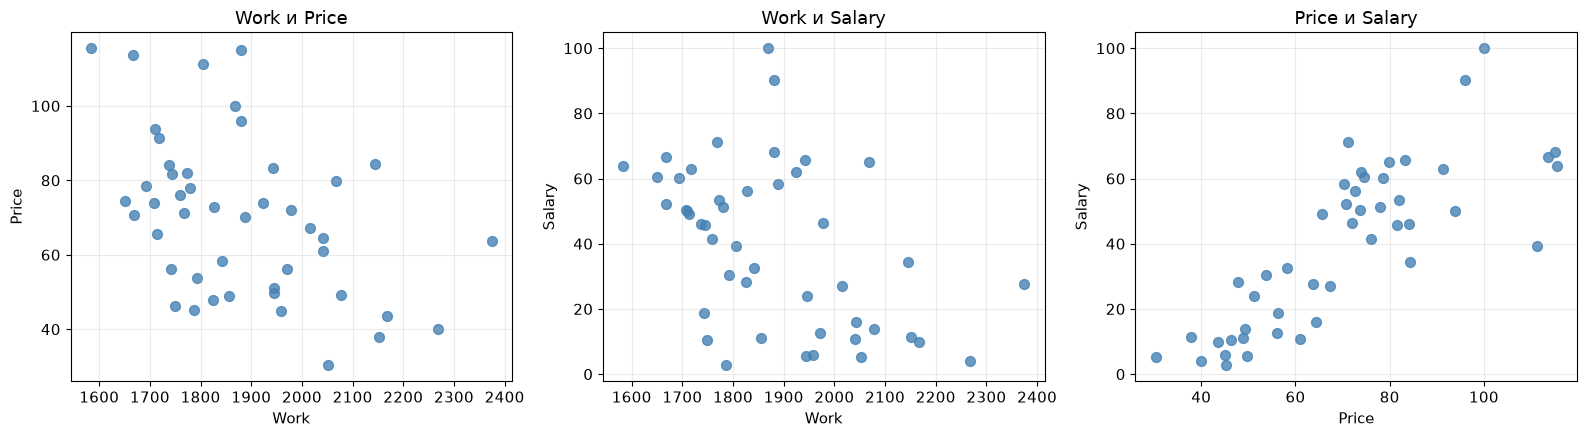

In [24]:
import matplotlib.pyplot as plt

# Задаём три пары признаков для сравнения.
pairs = [
    ("Work", "Price"),
    ("Work", "Salary"),
    ("Price", "Salary")
]

# Создаём три графика в одной строке.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Для каждой пары строим отдельную диаграмму рассеяния.
for ax, (x_feature, y_feature) in zip(axes, pairs):

    # Каждая точка соответствует одному городу.
    ax.scatter(
        cities[x_feature],
        cities[y_feature],
        color="steelblue",
        s=50,
        alpha=0.8
    )

    # Подписываем оси названиями признаков.
    ax.set_xlabel(x_feature)
    ax.set_ylabel(y_feature)

    # Указываем, какие показатели сравниваются.
    ax.set_title(f"{x_feature} и {y_feature}")

    # Добавляем сетку для удобства чтения.
    ax.grid(alpha=0.25)

# Подбираем расстояния между графиками.
plt.tight_layout()
plt.show()

## 5. Построение иерархии кластеров

Используется агломеративная иерархическая кластеризация.

В начале каждый город рассматривается как отдельный кластер.
Затем кластеры последовательно объединяются до получения
одной общей группы.

В качестве основного метода объединения выбран Ward.
Он минимизирует прирост внутрикластерной суммы квадратов
отклонений от центров при каждом объединении.

Расчёт проводится по трём стандартизированным признакам
с использованием евклидова расстояния.

Метод Ward подходит для поиска компактных групп. Его результат
далее будет оцениваться по дендрограмме и внутренним
показателям качества кластеризации.

In [25]:
from scipy.cluster.hierarchy import linkage, dendrogram

def build_hierarchy(data, method="ward", metric="euclidean"):
    """
    Строит иерархию объединения объектов.

    Параметры:
        data: числовая матрица объектов и признаков.
        method: способ объединения кластеров.
        metric: метрика расстояния между объектами.

    Возвращает:
        Матрицу, описывающую последовательность объединений.
    """

    # Метод Ward требует евклидовой метрики.
    if method == "ward" and metric != "euclidean":
        raise ValueError(
            "Для метода Ward необходимо использовать euclidean"
        )

    # Строим дерево объединений.
    # optimal_ordering улучшает порядок листьев для отображения,
    # сохраняя структуру объединений и их высоты.
    hierarchy = linkage(
        data,
        method=method,
        metric=metric,
        optimal_ordering=True
    )

    return hierarchy

In [26]:
# Выбираем параметры основного расчёта.
linkage_method = "ward"
distance_metric = "euclidean"

# Передаём стандартизированные признаки в функцию.
hierarchy = build_hierarchy(
    X_scaled,
    method=linkage_method,
    metric=distance_metric
)

# Проверяем размер результата.
print("Размер матрицы объединений:", hierarchy.shape)

Размер матрицы объединений: (45, 4)


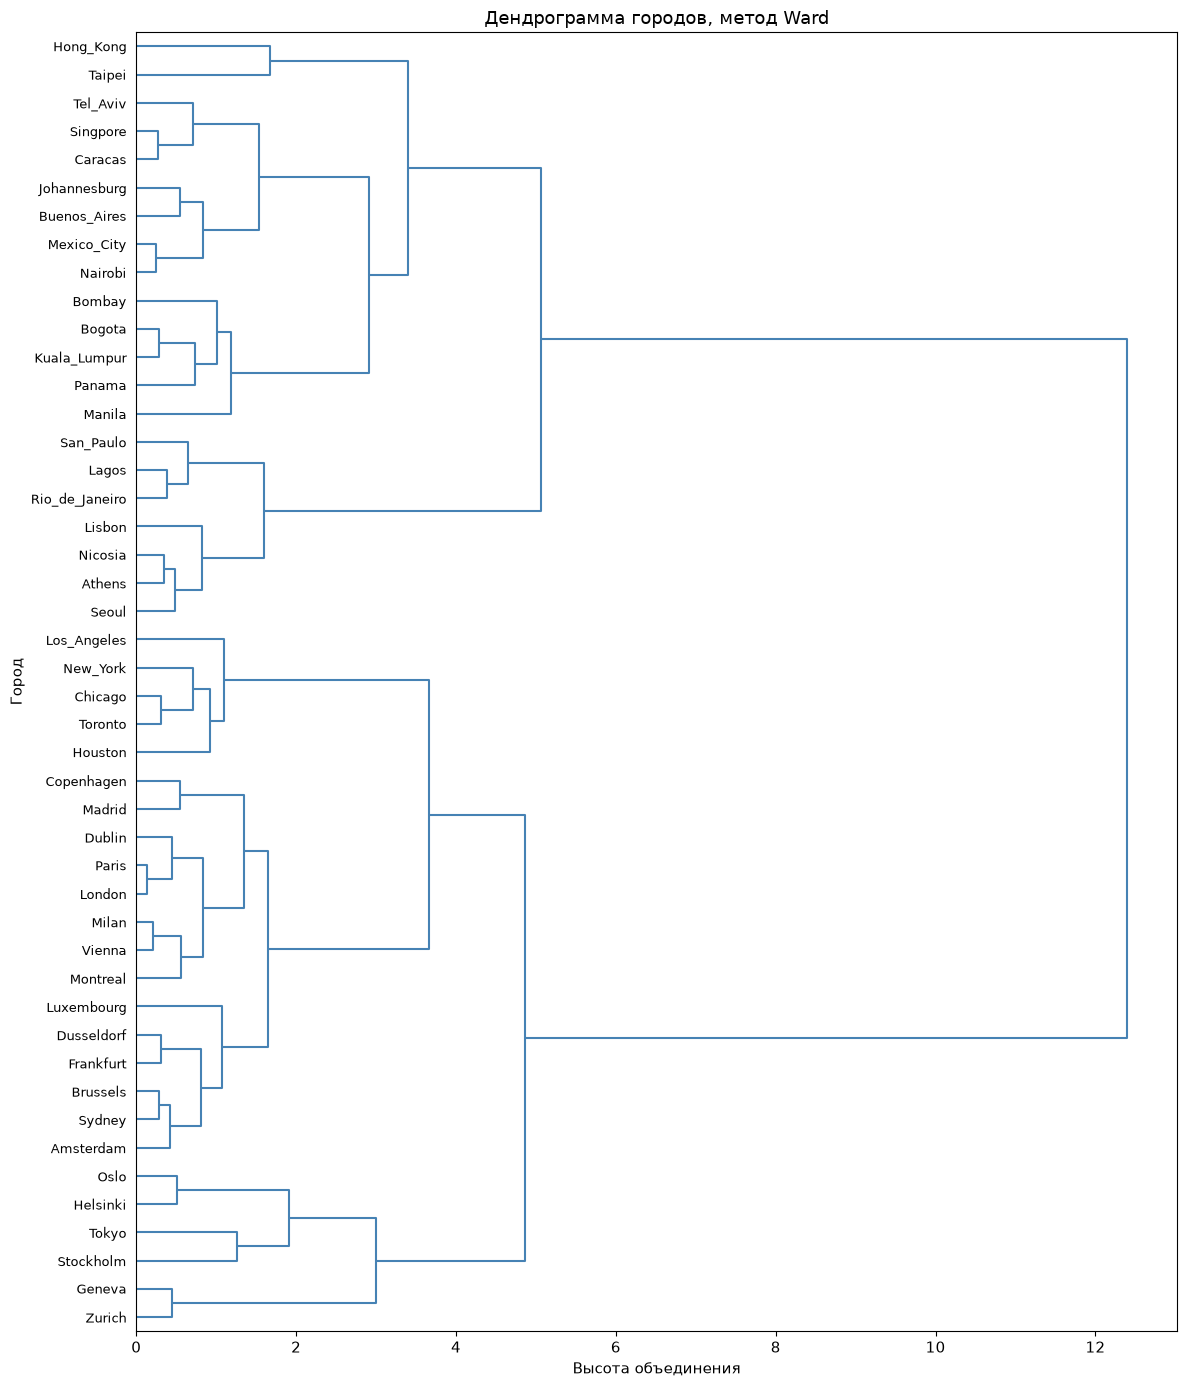

In [27]:
# Создаём высокий рисунок, чтобы названия 46 городов читались.
fig, ax = plt.subplots(figsize=(12, 14))

# Строим горизонтальную дендрограмму.
dendrogram(
    hierarchy,

    # Подписываем листья названиями городов.
    labels=cities["City"].to_numpy(),

    # Города располагаются слева, дерево растёт вправо.
    orientation="right",

    # Размер подписей городов.
    leaf_font_size=9,

    # Пока используем один цвет.
    # Число кластеров будем выбирать отдельно.
    link_color_func=lambda node_id: "steelblue",

    ax=ax
)

ax.set_title("Дендрограмма городов, метод Ward")
ax.set_xlabel("Высота объединения")
ax.set_ylabel("Город")

plt.tight_layout()
plt.show()

In [28]:
# Число исходных объектов.
n_objects = len(cities)

# Создаём таблицу всех шагов объединения.
merge_history = pd.DataFrame({
    "Шаг": np.arange(1, n_objects),
    "Высота объединения": hierarchy[:, 2],
    "Размер нового кластера": hierarchy[:, 3].astype(int),

    # После каждого объединения число кластеров уменьшается на один.
    "Кластеров после шага": np.arange(n_objects - 1, 0, -1)
})

# Показываем последние семь объединений.
display(merge_history.tail(7).round(3))

,Шаг,Высота объединения,Размер нового кластера,Кластеров после шага
38,39,2.911,12,7
39,40,2.994,6,6
40,41,3.402,14,5
41,42,3.660,19,4
42,43,4.860,25,3
43,44,5.061,21,2
44,45,12.400,46,1


### Предварительный анализ дендрограммы

Последнее объединение происходит на высоте около 12,40,
а предыдущее на высоте около 5,06.

Между этими объединениями наблюдается заметный скачок.
Это позволяет рассматривать разбиение на два кластера
как основной кандидат.

Окончательный выбор числа групп будет дополнительно
проверен с помощью внутренних показателей качества.
Одна дендрограмма не доказывает существование единственного
правильного разбиения.

## 6. Выбор числа кластеров

Для проверки предварительного решения сравним разбиения
на число групп от 2 до 8.

Этот диапазон позволяет рассмотреть как общую структуру,
так и более подробные варианты разделения 46 городов.
Он не охватывает все возможные разбиения.

Качество оценивается по среднему силуэту и показателям CH и DB.
Для силуэта и CH предпочтительны большие значения,
для DB предпочтительны меньшие значения.

Дополнительно рассматривается размер самой маленькой группы.

Эти показатели описывают геометрию кластеров.
Они не являются точностью относительно правильных меток,
поскольку такие метки в данных отсутствуют.

In [29]:
from scipy.cluster.hierarchy import fcluster

from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)


def compare_cluster_counts(data, hierarchy, k_values=range(2, 9)):
    """
    Сравнивает разбиения одного дерева на разное число кластеров.

    Параметры:
        data: матрица признаков, по которой построена иерархия.
        hierarchy: матрица объединений.
        k_values: проверяемые значения числа кластеров.

    Возвращает:
        Таблицу показателей для каждого разбиения.
    """

    # В этот список будем добавлять результаты каждого расчёта.
    results = []

    for k in k_values:

        # Получаем метки кластеров из готового дерева.
        # maxclust задаёт максимально допустимое число групп.
        labels = fcluster(
            hierarchy,
            t=k,
            criterion="maxclust"
        )

        # Проверяем фактически полученное число кластеров.
        # При совпадающих высотах оно может оказаться меньше k.
        actual_k = len(np.unique(labels))

        # Для расчёта метрик нужны хотя бы две группы,
        # но число групп должно быть меньше числа объектов.
        if not 2 <= actual_k < len(data):
            continue

        # Считаем число городов в каждой группе.
        cluster_sizes = pd.Series(labels).value_counts()

        # Сохраняем показатели текущего разбиения.
        results.append({
            "k_requested": k,
            "k_actual": actual_k,
            "silhouette": silhouette_score(
                data,
                labels,
                metric="euclidean"
            ),
            "CH": calinski_harabasz_score(data, labels),
            "DB": davies_bouldin_score(data, labels),
            "min_cluster_size": int(cluster_sizes.min())
        })

    return pd.DataFrame(results)

In [30]:
# Проверяем числа кластеров от 2 до 8 включительно.
# В range правая граница не включается.
k_values = range(2, 9)

# Рассчитываем показатели для каждого разбиения.
comparison = compare_cluster_counts(
    data=X_scaled,
    hierarchy=hierarchy,
    k_values=k_values
)

# Округляем только отображение таблицы.
display(comparison.round(4))

,k_requested,k_actual,silhouette,CH,DB,min_cluster_size
0,2,2,0.4705,55.3510,0.8076,21
1,3,3,0.3612,39.9168,0.8183,7
2,4,4,0.3551,38.9300,1.0024,6
3,5,5,0.3475,37.2093,0.9051,5
4,6,6,0.3657,37.9639,0.8894,2
5,7,7,0.3959,39.4112,0.7777,2
6,8,8,0.3990,43.5319,0.7740,2


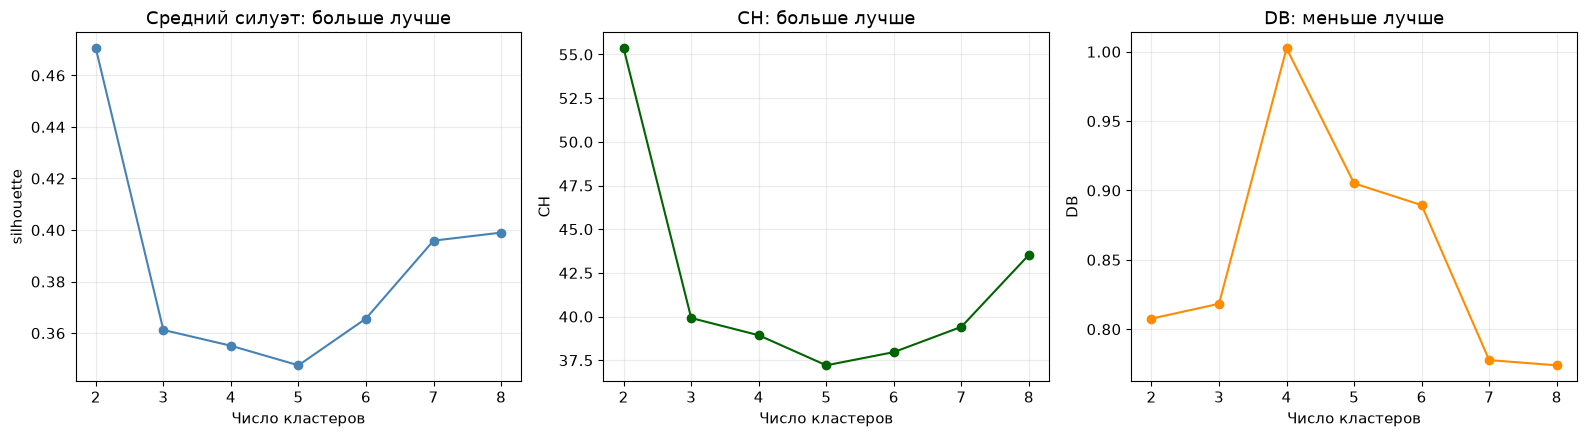

In [31]:
# Создаём отдельный график для каждого показателя.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Название столбца, заголовок графика и цвет линии.
metric_settings = [
    ("silhouette", "Средний силуэт: больше лучше", "steelblue"),
    ("CH", "CH: больше лучше", "darkgreen"),
    ("DB", "DB: меньше лучше", "darkorange")
]

for ax, (metric, title, color) in zip(axes, metric_settings):

    ax.plot(
        comparison["k_actual"],
        comparison[metric],
        marker="o",
        color=color
    )

    ax.set_title(title)
    ax.set_xlabel("Число кластеров")
    ax.set_ylabel(metric)

    # Показываем целые значения числа групп.
    ax.set_xticks(comparison["k_actual"])

    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [32]:
# idxmax возвращает индекс строки с максимальным значением.
best_silhouette = comparison.loc[
    comparison["silhouette"].idxmax()
]

best_ch = comparison.loc[
    comparison["CH"].idxmax()
]

# Для DB ищем минимальное значение.
best_db = comparison.loc[
    comparison["DB"].idxmin()
]

print(
    "Лучшее число групп по силуэту:",
    int(best_silhouette["k_actual"])
)

print(
    "Лучшее число групп по CH:",
    int(best_ch["k_actual"])
)

print(
    "Лучшее число групп по DB:",
    int(best_db["k_actual"])
)

Лучшее число групп по силуэту: 2
Лучшее число групп по CH: 2
Лучшее число групп по DB: 8


### Обоснование выбранного числа кластеров

Среди рассмотренных разбиений максимальный средний силуэт
получен при двух кластерах и составляет около 0,4705.
Показатель CH также принимает наибольшее значение при двух группах.

Показатель DB предпочитает более подробное разбиение
на восемь групп. Таким образом, критерии не дают
полностью одинакового результата.

Для дальнейшего анализа выбираются два кластера.
Выбор поддерживается средним силуэтом, показателем CH
и большим скачком высоты последнего объединения
на дендрограмме.

Содержательная интерпретация выбранного разбиения
будет выполнена по исходным экономическим показателям.

In [33]:
# Выбранное число кластеров.
n_clusters = 2

# Получаем метки из уже построенного дерева.
raw_labels = fcluster(
    hierarchy,
    t=n_clusters,
    criterion="maxclust"
)

# Создаём отдельную таблицу с результатами.
clustered_cities = cities.copy()

# Порядок меток соответствует порядку строк,
# использованному при построении X_scaled.
clustered_cities["Cluster"] = raw_labels

# Проверяем количество городов в каждой группе.
print("Количество городов по кластерам:")
display(
    clustered_cities["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Количество городов")
    .to_frame()
)

Количество городов по кластерам:


,Количество городов
Cluster,
1,25
2,21


## 7. Интерпретация кластеров

Для интерпретации рассмотрим состав групп и средние значения
экономических показателей.

Используются исходные значения Work, Price и Salary.
Стандартизированные значения применялись для расчёта расстояний,
а исходные единицы удобнее для экономического объяснения.

Номера кластеров являются условными обозначениями
и не отражают качество или положение города в рейтинге.

In [34]:
# Последовательно рассматриваем каждую группу.
for cluster_number, group in clustered_cities.groupby("Cluster"):

    # Показываем номер группы и количество городов.
    print(f"Кластер {cluster_number}: {len(group)} городов")

    # Сортируем названия по алфавиту и объединяем в одну строку.
    city_names = sorted(group["City"].tolist())
    print(", ".join(city_names))

    # Добавляем пустую строку между группами.
    print()

Кластер 1: 25 городов
Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los_Angeles, Luxembourg, Madrid, Milan, Montreal, New_York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich

Кластер 2: 21 городов
Athens, Bogota, Bombay, Buenos_Aires, Caracas, Hong_Kong, Johannesburg, Kuala_Lumpur, Lagos, Lisbon, Manila, Mexico_City, Nairobi, Nicosia, Panama, Rio_de_Janeiro, San_Paulo, Seoul, Singpore, Taipei, Tel_Aviv



In [35]:
# Для каждого кластера рассчитываем число городов
# и средние значения трёх исходных признаков.
cluster_summary = clustered_cities.groupby("Cluster").agg(
    City_count=("City", "count"),
    Work_mean=("Work", "mean"),
    Price_mean=("Price", "mean"),
    Salary_mean=("Salary", "mean")
)

# Показываем результат с округлением до двух знаков.
display(cluster_summary.round(2))

,City_count,Work_mean,Price_mean,Salary_mean
Cluster,,,,
1,25,1789.24,84.97,59.03
2,21,1987.86,52.40,16.35


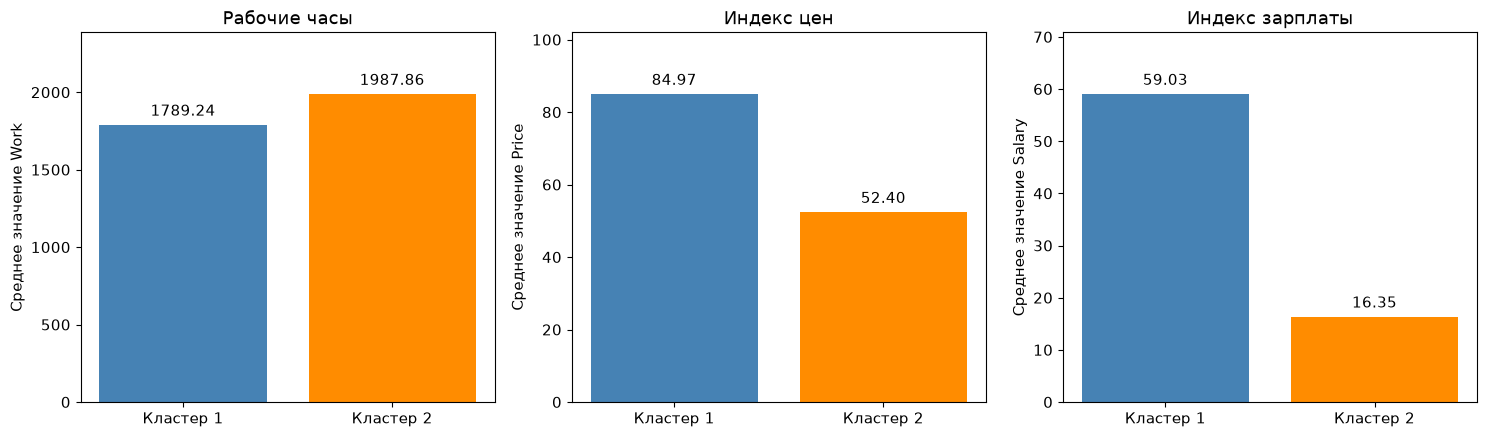

In [36]:
# Создаём три панели в одном рисунке.
# Для каждого показателя используем отдельную шкалу.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Настройки: столбец таблицы, заголовок и подпись оси.
plot_settings = [
    ("Work_mean", "Рабочие часы", "Среднее значение Work"),
    ("Price_mean", "Индекс цен", "Среднее значение Price"),
    ("Salary_mean", "Индекс зарплаты", "Среднее значение Salary")
]

# Подписи групп на горизонтальной оси.
cluster_names = [
    f"Кластер {number}"
    for number in cluster_summary.index
]

for ax, (column, title, ylabel) in zip(axes, plot_settings):

    # Получаем средние значения выбранного показателя.
    values = cluster_summary[column]

    # Строим столбцы для двух кластеров.
    bars = ax.bar(
        cluster_names,
        values,
        color=["steelblue", "darkorange"]
    )

    # Подписываем значения над столбцами.
    ax.bar_label(bars, fmt="%.2f", padding=4)

    ax.set_title(title)
    ax.set_ylabel(ylabel)

    # Начинаем шкалу с нуля.
    # Сверху оставляем место для подписей.
    ax.set_ylim(0, values.max() * 1.2)

# Располагаем панели так, чтобы подписи не перекрывались.
plt.tight_layout()
plt.show()

### Характеристика полученных групп

Кластер 1 включает 25 городов. Среднее значение Work составляет
1789,24, индекс цен составляет 84,97, а индекс зарплаты 59,03.

По сравнению со второй группой эти города характеризуются
более высокими ценами и оплатой труда при меньшем среднем
числе рабочих часов.

Кластер 2 включает 21 город. Среднее значение Work составляет
1987,86, индекс цен составляет 52,40, а индекс зарплаты 16,35.

Для этой группы характерны более низкие цены и оплата труда
при большей средней рабочей нагрузке.

Таким образом, группы различаются сочетанием всех трёх
показателей. Более низкие цены во второй группе сопровождаются
также существенно меньшим индексом зарплаты.

Приведённые характеристики относятся к средним значениям
по группам и не обязательно выполняются для каждого города.
Результат описывает рассматриваемую выборку за 1991 год
и не является оценкой современного состояния городов.

## Выводы

В работе выполнен иерархический кластерный анализ экономических
показателей городов за 1991 год.

После проверки данных из основного анализа исключены Cairo
и Jakarta, поскольку у каждого города отсутствуют два признака
из трёх. Для кластеризации использованы 46 полных наблюдений.

Признаки Work, Price и Salary стандартизированы, чтобы различия
масштабов не определяли основную часть расстояний между городами.

Иерархия построена методом Ward с евклидовым расстоянием.
Выбрано разбиение на два кластера. Оно поддерживается заметным
скачком высоты последнего объединения, максимальным средним
силуэтом около 0,4705 и максимальным CH среди проверенных
вариантов от двух до восьми групп. Показатель DB предпочитает
более подробное разбиение, поэтому выбор сделан по совокупности
результатов.

Получены группы из 25 и 21 города. Первая группа характеризуется
более высокими индексами цен и зарплаты при меньшем среднем
числе рабочих часов. Во второй группе цены и зарплата ниже,
а средняя рабочая нагрузка выше.

Результаты ограничены составом выборки, выбранными признаками
и способом расчёта расстояний. Кластеризация показывает сходство
экономических условий, но не объясняет причины различий.